# 다음 영화 리뷰 데이터 분석
 1. 데이터 로딩
 2. 텍스트 전처리
 3. 빈도수 계산
 4. 시각화

In [3]:
# 데이터 로팅
datafile = "daum_movie_review.csv"
import pandas as pd
df = pd.read_csv(datafile)
df.head()

,review,rating,date,title
0,돈 들인건 티가 나지만 보는 내내 하품만,1,2018.10.29,인피니티 워
1,몰입할수밖에 없다. 어렵게 생각할 필요없다. 내가 전투에 참여한듯 손에 땀이남.,10,2018.10.26,인피니티 워
2,이전 작품에 비해 더 화려하고 스케일도 커졌지만.... 전국 맛집의 음식들을 한데 ...,8,2018.10.24,인피니티 워
3,이 정도면 볼만하다고 할 수 있음!,8,2018.10.22,인피니티 워
4,재미있다,10,2018.10.20,인피니티 워


In [4]:
# 품사 태깅 -> 토큰화, 불용어제거
from konlpy.tag import Okt

tagger = Okt()
reviews = list(df.review)

pos_list = []
for review in reviews:
    tokens = tagger.pos(review)
    pos_list.append(tokens)


In [5]:
pos_list[:1]

[[('돈', 'Noun'),
  ('들인건', 'Verb'),
  ('티', 'Noun'),
  ('가', 'Josa'),
  ('나', 'Noun'),
  ('지만', 'Josa'),
  ('보는', 'Verb'),
  ('내내', 'Noun'),
  ('하품', 'Noun'),
  ('만', 'Josa')]]

In [6]:
my_tags = ['Noun','Verb','Adjective']
result_list = []
for review in pos_list:
    for word, tag in review:
        if tag in my_tags:
            result_list.append(word)
result_list[:10]

['돈', '들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다']

In [9]:
from collections import Counter
counter = Counter(result_list)
count_list = counter.most_common(5)
print(count_list)


[('영화', 6691), ('연기', 1293), ('감동', 1223), ('생각', 1027), ('정말', 948)]


findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font famil

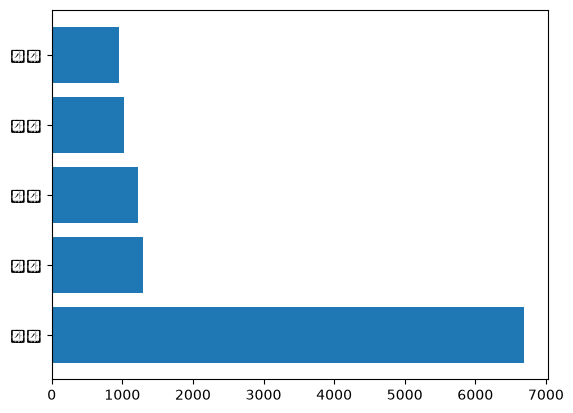

In [11]:


font_path = '/mnt/c/Windows/Fonts/malgun.ttf'

from matplotlib import font_manager, rc
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)
import matplotlib.pyplot as plt
x = [word for word, count in count_list]
y = [count for word, count in count_list]
plt.barh(x,y)
plt.show()